# 06 · Evaluación con el conjunto de PRUEBA (tarea 2.5, CRISP-DM fase 5) — EJECUCIÓN ÚNICA

Reglas: `docs/sprint2/plan_evaluacion.md`. Métricas y objetivos: `docs/sprint2/06_metricas.md`.

- Modelo final: **FaceNet VGGFace2 congelado** con el umbral **oficial 0,5514** y el punto secundario 0,595, solo para reportar.
- Control: **(a2) ResNet-18 ImageNet** con umbral 0,8769, solo para reportar.
- Umbrales y plantillas vienen de los paquetes de las tareas 2.2 y 2.3, y **aquí no se recalcula ni se ajusta nada**.
- Comparaciones: 299 genuinas, 7 848 impostoras externas y 6 877 internas. Se desglosa a Marmik y a Kashyap.

**Protección:** este cuaderno se niega a ejecutarse si no se define la variable de entorno `FACEID_EJECUTAR_PRUEBA=SI`.
Si ya existen resultados de prueba, exige además `FACEID_MOTIVO_REEJECUCION` con el motivo, que queda registrado.
Ejecución prevista (desde la raíz del proyecto, en PowerShell):

```
$env:FACEID_EJECUTAR_PRUEBA = "SI"; .venv/Scripts/python -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 notebooks/06_evaluacion_prueba.ipynb
```

In [1]:
import os, sys, json, time, subprocess, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C
SALIDA = C.DOCS / "07_resultados_prueba.json"
if os.environ.get("FACEID_EJECUTAR_PRUEBA") != "SI":
    raise RuntimeError("Evaluación de PRUEBA bloqueada: define FACEID_EJECUTAR_PRUEBA=SI solo cuando el usuario lo autorice.")
MOTIVO = os.environ.get("FACEID_MOTIVO_REEJECUCION")
if SALIDA.exists() and not MOTIVO:
    raise RuntimeError(f"Ya existe {SALIDA.name}: la prueba es de ejecución única. Para re-ejecutar (p. ej. por un error de código) define FACEID_MOTIVO_REEJECUCION.")
git = lambda *a: subprocess.run(["git", *a], cwd=ROOT, capture_output=True, text=True).stdout.strip()
REGISTRO = {"commit": git("rev-parse", "HEAD"), "arbol_limpio": git("status", "--porcelain") == "",
            "inicio": time.strftime("%Y-%m-%d %H:%M:%S"), "motivo_reejecucion": MOTIVO, "maquina": platform.node()}
print(REGISTRO)
assert REGISTRO["arbol_limpio"], "Hay cambios sin commitear: commitea antes de ejecutar la prueba para que quede trazable."
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import data as D, metrics as MT, verification as V, pipeline as P, evaluation as EV
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
DEV = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
pd.set_option("display.width", 200)

{'commit': '0a27e3db0d5053a9976d21f97fbb1dafd76c949c', 'arbol_limpio': True, 'inicio': '2026-10-23 11:57:40', 'motivo_reejecucion': None, 'maquina': 'DESKTOP-O2RJSM1'}


## 1. Paquetes, umbrales fijados y objetivos (no se modifican)

In [2]:
PKG = {"facenet": C.MODELS_DIR / "verificador_facenet_vggface2", "control_a2": C.MODELS_DIR / "control_resnet18_imagenet"}
NOM = {"facenet": "FaceNet VGGFace2 (final)", "control_a2": "Control (a2) ResNet-18 ImageNet"}
VF = {k: P.Verifier(p, device=DEV) for k, p in PKG.items()}
# Umbrales fijados en plan_evaluacion.md (commit 9b06c8e); se comprueba que el config.json no ha cambiado
ESPERADO = {"facenet": 0.551421, "control_a2": 0.87693}
for k in VF:
    assert VF[k].cfg["umbral_estado"] == "propuesto en validación"
    assert abs(VF[k].threshold - ESPERADO[k]) < 1e-9, (k, VF[k].threshold)
UMBRALES = {"facenet": {"oficial 0,5514": VF["facenet"].threshold, "secundario 0,595": 0.595},
            "control_a2": {"control 0,8769": VF["control_a2"].threshold}}
OBJ = {"FAR_max": 0.05, "FRR_max": 0.10, "exactitud_balanceada_min": 0.90, "tiempo_max_s": 3.0}   # 06_metricas.md (pendientes de confirmar con el docente)
print(UMBRALES, OBJ)

{'facenet': {'oficial 0,5514': 0.551421, 'secundario 0,595': 0.595}, 'control_a2': {'control 0,8769': 0.87693}} {'FAR_max': 0.05, 'FRR_max': 0.1, 'exactitud_balanceada_min': 0.9, 'tiempo_max_s': 3.0}


## 2. Conjunto de prueba (primera y única carga)

In [3]:
sp = D.load_split_table()
REG = sorted(sp.loc[sp.role == "registrada", "person"].unique())
assert REG == VF["facenet"].users == VF["control_a2"].users
te = sp[sp.split == "test"].reset_index(drop=True)
assert (te.role == "registrada").sum() == 299 and (te.role == "impostora_test").sum() == 327
assert not set(te.filename) & set(sp.loc[sp.split != "test", "filename"])
cache = np.load(C.DATA_PROCESSED / "faces160.npz", allow_pickle=True)
pos = {f: k for k, f in enumerate(cache["filename"])}
X_te = cache["X"][[pos[f] for f in te.filename]]; del cache
print(f"Prueba: {len(te)} imágenes | registradas {(te.role=='registrada').sum()} | impostoras {sorted(te.loc[te.role!='registrada','person'].unique())}")

Prueba: 626 imágenes | registradas 299 | impostoras ['Courtney Cox', 'Hugh Jackman', 'Kashyap', 'Natalie Portman']


## 3. Puntuaciones y métricas en los umbrales fijados

In [4]:
S, SC, FILAS = {}, {}, []
for k in VF:
    E = np.concatenate([VF[k].embed(X_te[i:i+128]).cpu().numpy() for i in range(0, len(X_te), 128)])
    S[k] = E @ VF[k].T.cpu().numpy().T          # plantillas de train guardadas en el paquete (tarea 2.2)
    rows, SC[k] = EV.evaluate(S[k], te.person.values, te.role.values, REG, UMBRALES[k])
    for r in rows: r["modelo"] = NOM[k]
    FILAS += rows
assert len(SC["facenet"]["genuinas"]) == 299 and len(SC["facenet"]["impostoras"]) == 7848 and len(SC["facenet"]["internas"]) == 6877
res = pd.DataFrame(FILAS)
cols = ["modelo", "punto_operacion", "impostoras", "umbral", "n_genuinas", "n_impostoras", "TA", "FR", "FA", "TR", "FAR", "FAR_IC95", "FRR", "FRR_IC95",
        "exactitud_balanceada", "exactitud_simple", "proporcion_genuinas", "EER", "AUC", "genuina_min", "impostora_max"]
res[cols].to_csv(C.DOCS / "07_metricas_prueba.csv", index=False)
fmt = res[cols].copy()
for c in ["FAR", "FRR", "exactitud_balanceada", "exactitud_simple", "proporcion_genuinas", "EER"]: fmt[c] = (fmt[c]*100).round(3)
for c in ["FAR_IC95", "FRR_IC95"]: fmt[c] = fmt[c].map(lambda t: f"{t[0]*100:.3f}–{t[1]*100:.3f}")
fmt.round(4)

,modelo,punto_operacion,impostoras,umbral,n_genuinas,n_impostoras,TA,FR,FA,TR,...,FAR_IC95,FRR,FRR_IC95,exactitud_balanceada,exactitud_simple,proporcion_genuinas,EER,AUC,genuina_min,impostora_max
0,FaceNet VGGFace2 (final),"oficial 0,5514",externas,0.5514,299,7848,296,3,3,7845,...,0.008–0.112,1.003,0.207–2.904,99.479,99.926,3.670,0.358,0.9999,0.4017,0.6285
1,FaceNet VGGFace2 (final),"oficial 0,5514",internas,0.5514,299,6877,296,3,3,6874,...,0.009–0.127,1.003,0.207–2.904,99.477,99.916,4.167,0.647,0.9999,0.4017,0.5961
2,FaceNet VGGFace2 (final),"oficial 0,5514",todas (ext+int),0.5514,299,14725,296,3,6,14719,...,0.015–0.089,1.003,0.207–2.904,99.478,99.940,1.990,0.671,0.9999,0.4017,0.6285
3,FaceNet VGGFace2 (final),"secundario 0,595",externas,0.5950,299,7848,294,5,1,7847,...,0.000–0.071,1.672,0.545–3.859,99.158,99.926,3.670,0.358,0.9999,0.4017,0.6285
4,FaceNet VGGFace2 (final),"secundario 0,595",internas,0.5950,299,6877,294,5,1,6876,...,0.000–0.081,1.672,0.545–3.859,99.157,99.916,4.167,0.647,0.9999,0.4017,0.5961
5,FaceNet VGGFace2 (final),"secundario 0,595",todas (ext+int),0.5950,299,14725,294,5,2,14723,...,0.002–0.049,1.672,0.545–3.859,99.157,99.953,1.990,0.671,0.9999,0.4017,0.6285
6,Control (a2) ResNet-18 ImageNet,"control 0,8769",externas,0.8769,299,7848,219,80,12,7836,...,0.079–0.267,26.756,21.823–32.156,86.546,98.871,3.670,5.300,0.9886,0.5686,0.9125
7,Control (a2) ResNet-18 ImageNet,"control 0,8769",internas,0.8769,299,6877,219,80,0,6877,...,0.000–0.054,26.756,21.823–32.156,86.622,98.885,4.167,1.709,0.9981,0.5686,0.8423
8,Control (a2) ResNet-18 ImageNet,"control 0,8769",todas (ext+int),0.8769,299,14725,219,80,12,14713,...,0.042–0.142,26.756,21.823–32.156,86.581,99.388,1.990,3.993,0.9930,0.5686,0.9125


## 4. Matrices de confusión (todas las impostoras)

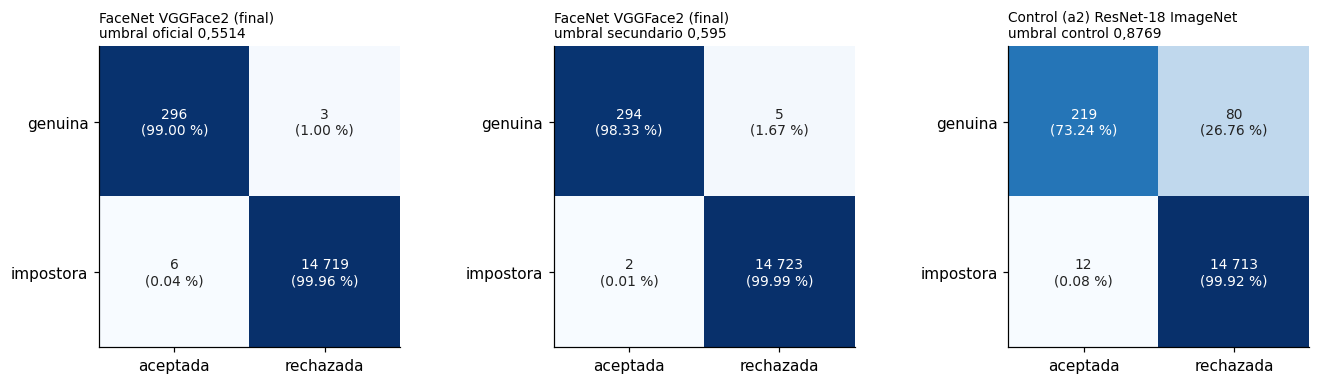

In [5]:
sel = res[res.impostoras == "todas (ext+int)"].reset_index(drop=True)
fig, axes = plt.subplots(1, len(sel), figsize=(4.2 * len(sel), 3.6))
for a, (_, r) in zip(np.atleast_1d(axes), sel.iterrows()):
    M = np.array([[r.TA, r.FR], [r.FA, r.TR]])
    a.imshow(M / M.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); a.grid(False)
    for i in range(2):
        for j in range(2):
            v = M[i, j] / M[i].sum()
            a.text(j, i, f"{M[i, j]:,}\n({v*100:.2f} %)".replace(",", " "), ha="center", va="center", fontsize=9, color="white" if v > 0.5 else "#222")
    a.set_xticks([0, 1]); a.set_xticklabels(["aceptada", "rechazada"]); a.set_yticks([0, 1]); a.set_yticklabels(["genuina", "impostora"])
    a.set_title(f"{r.modelo}\numbral {r.punto_operacion}", fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(C.FIGS / "07_matrices_confusion_prueba.png"); plt.show()

## 5. ROC, DET y distribución de puntuaciones (descriptivas)

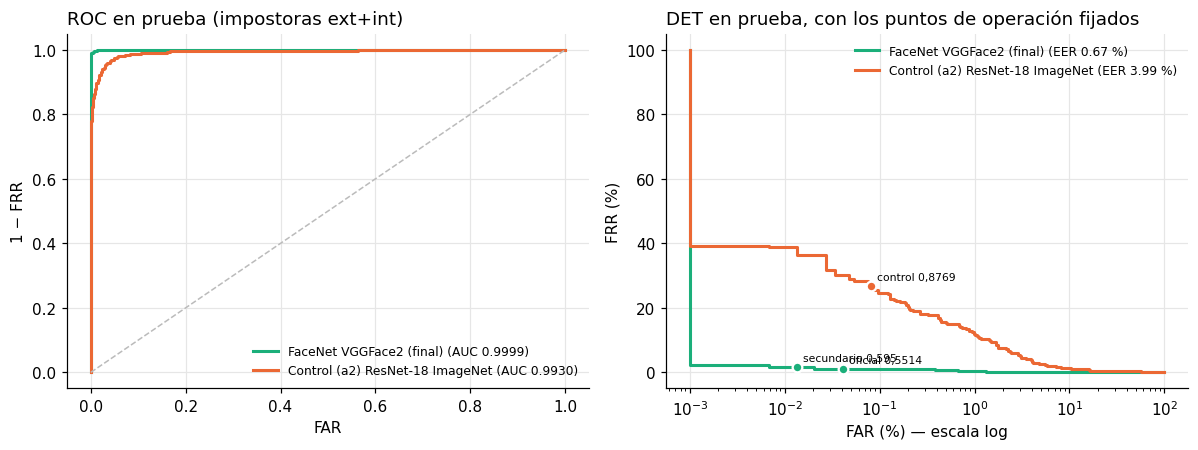

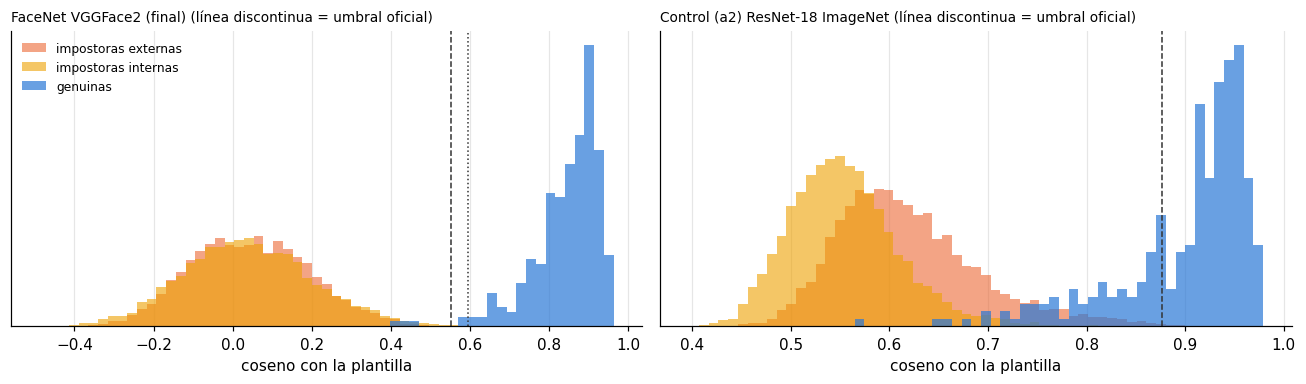

In [6]:
COL = {"facenet": "#1baf7a", "control_a2": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k in VF:
    g, i = SC[k]["genuinas"], np.r_[SC[k]["impostoras"], SC[k]["internas"]]
    fpr, tpr, _ = MT.roc(g, i); e = MT.eer(g, i)[0]
    axes[0].plot(fpr, tpr, color=COL[k], lw=2, label=f"{NOM[k]} (AUC {MT.auc(g, i):.4f})")
    axes[1].plot(np.maximum(fpr, 1e-5) * 100, (1 - tpr) * 100, color=COL[k], lw=2, label=f"{NOM[k]} (EER {e*100:.2f} %)")
    for tn, t in UMBRALES[k].items():
        far, frr = MT.far_frr(g, i, t)
        axes[1].scatter([max(far, 1e-5) * 100], [frr * 100], color=COL[k], s=40, zorder=3, edgecolor="white", linewidth=1.5)
        axes[1].annotate(tn, (max(far, 1e-5) * 100, frr * 100), fontsize=7, xytext=(4, 4), textcoords="offset points")
axes[0].plot([0, 1], [0, 1], color="#bbb", ls="--", lw=1); axes[0].set_xlabel("FAR"); axes[0].set_ylabel("1 − FRR")
axes[0].set_title("ROC en prueba (impostoras ext+int)", loc="left"); axes[0].legend(frameon=False, fontsize=8, loc="lower right")
axes[1].set_xscale("log"); axes[1].set_xlabel("FAR (%) — escala log"); axes[1].set_ylabel("FRR (%)")
axes[1].set_title("DET en prueba, con los puntos de operación fijados", loc="left"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(C.FIGS / "07_roc_det_prueba.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for a, k in zip(axes, VF):
    sc = SC[k]; allv = np.r_[sc["genuinas"], sc["impostoras"], sc["internas"]]; b = np.linspace(allv.min(), allv.max(), 60)
    a.hist(sc["impostoras"], bins=b, density=True, color="#eb6834", alpha=0.6, label="impostoras externas")
    a.hist(sc["internas"], bins=b, density=True, color="#eda100", alpha=0.6, label="impostoras internas")
    a.hist(sc["genuinas"], bins=b, density=True, color="#2a78d6", alpha=0.7, label="genuinas")
    for tn, t in UMBRALES[k].items(): a.axvline(t, color="#333", lw=1, ls="--" if "oficial" in tn or "control" in tn else ":")
    a.set_title(f"{NOM[k]} (línea discontinua = umbral oficial)", loc="left", fontsize=9); a.set_yticks([]); a.set_xlabel("coseno con la plantilla")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(C.FIGS / "07_distribucion_puntuaciones_prueba.png"); plt.show()

## 6. Desglose: Marmik (registrada no famosa) y Kashyap (impostora no famosa)

**Cada grupo es una sola persona.** Marmik tiene 5 comparaciones genuinas y Kashyap 720 comparaciones impostoras, pero de solo 30 fotos.
Es una **señal cualitativa y no permite conclusiones firmes** sobre el sesgo de famosos.

In [7]:
GR = []
for k in VF:
    for tn, t in UMBRALES[k].items():
        for r in EV.group_breakdown(SC[k], te.person.values, REG, t, "Marmik", "Kashyap"):
            r.update({"modelo": NOM[k], "punto_operacion": tn}); GR.append(r)
gr = pd.DataFrame(GR); gr.to_csv(C.DOCS / "07_desglose_marmik_kashyap.csv", index=False)
g2 = gr.copy(); g2["tasa_%"] = (g2.tasa * 100).round(3); g2["IC95_%"] = g2.IC95.map(lambda t: f"{t[0]*100:.2f}–{t[1]*100:.2f}")
g2[["modelo", "punto_operacion", "grupo", "metrica", "errores", "n", "tasa_%", "IC95_%", "puntuacion_min", "puntuacion_mediana", "puntuacion_max"]].round(3)

,modelo,punto_operacion,grupo,metrica,errores,n,tasa_%,IC95_%,puntuacion_min,puntuacion_mediana,puntuacion_max
0,FaceNet VGGFace2 (final),"oficial 0,5514",genuinas Marmik,FRR,0,5,0.000,0.00–52.18,0.660,0.773,0.881
1,FaceNet VGGFace2 (final),"oficial 0,5514",genuinas demás registradas,FRR,3,294,1.020,0.21–2.95,0.402,0.868,0.963
2,FaceNet VGGFace2 (final),"oficial 0,5514",impostoras externas Kashyap,FAR,2,720,0.278,0.03–1.00,-0.337,0.058,0.628
3,FaceNet VGGFace2 (final),"oficial 0,5514",impostoras externas demás,FAR,1,7128,0.014,0.00–0.08,-0.407,0.040,0.594
4,FaceNet VGGFace2 (final),"oficial 0,5514",internas: Marmik se hace pasar por otro,FAR,0,115,0.000,0.00–3.16,-0.319,0.015,0.369
5,FaceNet VGGFace2 (final),"oficial 0,5514",internas: demás registradas,FAR,3,6762,0.044,0.01–0.13,-0.488,0.033,0.596
6,FaceNet VGGFace2 (final),"secundario 0,595",genuinas Marmik,FRR,0,5,0.000,0.00–52.18,0.660,0.773,0.881
7,FaceNet VGGFace2 (final),"secundario 0,595",genuinas demás registradas,FRR,5,294,1.701,0.55–3.92,0.402,0.868,0.963
8,FaceNet VGGFace2 (final),"secundario 0,595",impostoras externas Kashyap,FAR,1,720,0.139,0.00–0.77,-0.337,0.058,0.628
9,FaceNet VGGFace2 (final),"secundario 0,595",impostoras externas demás,FAR,0,7128,0.000,0.00–0.05,-0.407,0.040,0.594


In [8]:
por_id = []
for k in VF:
    t = list(UMBRALES[k].values())[0]; sc = SC[k]
    pg = te.person.values[sc["genuinas_pares"][:, 0]]
    for p in REG:
        s = sc["genuinas"][pg == p]
        por_id.append({"modelo": NOM[k], "persona": p, "tipo": "registrada (FRR)", "n": len(s), "errores": int((s < t).sum()), "puntuacion_min": s.min()})
    pi = te.person.values[sc["impostoras_pares"][:, 0]]
    for p in sorted(set(pi)):
        s = sc["impostoras"][pi == p]
        por_id.append({"modelo": NOM[k], "persona": p, "tipo": "impostora externa (FAR)", "n": len(s), "errores": int((s >= t).sum()), "puntuacion_max": s.max()})
por_id = pd.DataFrame(por_id); por_id["tasa_%"] = por_id.errores / por_id.n * 100
por_id.to_csv(C.DOCS / "07_por_identidad_prueba.csv", index=False)
por_id[por_id.errores > 0].round(3)

,modelo,persona,tipo,n,errores,puntuacion_min,puntuacion_max,tasa_%
5,FaceNet VGGFace2 (final),Billie Eilish,registrada (FRR),15,2,0.436,NaN,13.333
23,FaceNet VGGFace2 (final),Zac Efron,registrada (FRR),14,1,0.402,NaN,7.143
24,FaceNet VGGFace2 (final),Courtney Cox,impostora externa (FAR),1920,1,NaN,0.594,0.052
26,FaceNet VGGFace2 (final),Kashyap,impostora externa (FAR),720,2,NaN,0.628,0.278
28,Control (a2) ResNet-18 ImageNet,Akshay Kumar,registrada (FRR),8,5,0.751,NaN,62.500
29,Control (a2) ResNet-18 ImageNet,Alexandra Daddario,registrada (FRR),14,3,0.835,NaN,21.429
30,Control (a2) ResNet-18 ImageNet,Alia Bhatt,registrada (FRR),12,4,0.726,NaN,33.333
32,Control (a2) ResNet-18 ImageNet,Anushka Sharma,registrada (FRR),10,6,0.716,NaN,60.000
33,Control (a2) ResNet-18 ImageNet,Billie Eilish,registrada (FRR),15,8,0.770,NaN,53.333
34,Control (a2) ResNet-18 ImageNet,Brad Pitt,registrada (FRR),18,3,0.695,NaN,16.667


In [9]:
dif = []
for tipo, key in [("externa", "impostoras"), ("interna", "internas")]:
    pr, s = SC["facenet"][key + "_pares"], SC["facenet"][key]
    for j in np.argsort(-s)[:10]:
        dif.append({"tipo": tipo, "foto": te.filename[pr[j, 0]], "persona_real": te.person[pr[j, 0]], "dice_ser": REG[pr[j, 1]], "puntuacion": s[j]})
pr, s = SC["facenet"]["genuinas_pares"], SC["facenet"]["genuinas"]
for j in np.argsort(s)[:10]:
    dif.append({"tipo": "genuina (más baja)", "foto": te.filename[pr[j, 0]], "persona_real": te.person[pr[j, 0]], "dice_ser": REG[pr[j, 1]], "puntuacion": s[j]})
dif = pd.DataFrame(dif); dif.to_csv(C.DOCS / "07_casos_extremos_facenet_prueba.csv", index=False); dif.round(3)

,tipo,foto,persona_real,dice_ser,puntuacion
0,externa,Kashyap_25.jpg,Kashyap,Marmik,0.628
1,externa,Courtney Cox_58.jpg,Courtney Cox,Charlize Theron,0.594
2,externa,Kashyap_17.jpg,Kashyap,Marmik,0.566
3,externa,Kashyap_22.jpg,Kashyap,Marmik,0.533
4,externa,Hugh Jackman_63.jpg,Hugh Jackman,Robert Downey Jr,0.529
5,externa,Kashyap_19.jpg,Kashyap,Marmik,0.518
6,externa,Kashyap_29.jpg,Kashyap,Marmik,0.499
7,externa,Natalie Portman_27.jpg,Natalie Portman,Margot Robbie,0.496
8,externa,Hugh Jackman_94.jpg,Hugh Jackman,Lisa Kudrow,0.495
9,externa,Kashyap_18.jpg,Kashyap,Marmik,0.493


## 7. Tiempo por verificación (imágenes de prueba; mismo método que en 2.1 y 2.2)

In [10]:
def cron(f, n=60, warm=5):
    t = []
    for j in range(n + warm):
        t0 = time.perf_counter(); f(j); dt = time.perf_counter() - t0
        if j >= warm: t.append(dt)
    return float(np.median(t)), float(np.percentile(t, 95))
paths = te.filename.map(lambda f: str(C.FACES_DIR / f)).values
rng = np.random.default_rng(C.SEED); idx = rng.choice(len(paths), 65)
TIEMPO = []
for k, folder in PKG.items():
    for dev in ([DEV] if DEV == "cuda" else []) + ["cpu"]:
        v = P.Verifier(folder, device=dev)
        med, p95 = cron(lambda j: v.verify_path(paths[idx[j]], REG[j % len(REG)]))
        TIEMPO.append({"modelo": NOM[k], "dispositivo": "GPU" if dev == "cuda" else "CPU", "mediana_s": med, "p95_s": p95})
TIEMPO = pd.DataFrame(TIEMPO); TIEMPO.to_csv(C.DOCS / "07_tiempos_prueba.csv", index=False); TIEMPO.round(4)

,modelo,dispositivo,mediana_s,p95_s
0,FaceNet VGGFace2 (final),GPU,0.0202,0.0406
1,FaceNet VGGFace2 (final),CPU,0.0615,0.0730
2,Control (a2) ResNet-18 ImageNet,GPU,0.0064,0.0083
3,Control (a2) ResNet-18 ImageNet,CPU,0.0505,0.0850


## 8. Comparación con los objetivos (umbral oficial de FaceNet, todas las impostoras)

In [11]:
r_of = res[(res.modelo == NOM["facenet"]) & (res.punto_operacion == "oficial 0,5514") & (res.impostoras == "todas (ext+int)")].iloc[0]
t_cpu_p95 = TIEMPO[(TIEMPO.modelo == NOM["facenet"]) & (TIEMPO.dispositivo == "CPU")].p95_s.iloc[0]
chk = EV.check_objectives(r_of, OBJ, t_cpu_p95)
obj = pd.DataFrame([{"metrica": m, "valor": v, "condicion": f"{op} {o}", "cumple": c} for m, (v, op, o, c) in chk.items()])
obj.loc[len(obj)] = {"metrica": "exactitud_simple (solo informativa)", "valor": r_of.exactitud_simple, "condicion": "—", "cumple": None}
obj.loc[len(obj)] = {"metrica": "proporción genuinas", "valor": r_of.proporcion_genuinas, "condicion": "—", "cumple": None}
obj.loc[len(obj)] = {"metrica": "EER (descriptivo)", "valor": r_of.EER, "condicion": "sin objetivo", "cumple": None}
obj.to_csv(C.DOCS / "07_objetivos_prueba.csv", index=False)
print("Objetivos pendientes de confirmar con el docente (06_metricas.md)."); obj

Objetivos pendientes de confirmar con el docente (06_metricas.md).


,metrica,valor,condicion,cumple
0,FAR,0.000407,<= 0.05,True
1,FRR,0.010033,<= 0.1,True
2,exactitud_balanceada,0.994780,>= 0.9,True
3,tiempo_verificacion_s,0.073006,<= 3.0,True
4,exactitud_simple (solo informativa),0.999401,—,None
5,proporción genuinas,0.019901,—,None
6,EER (descriptivo),0.006706,sin objetivo,None


## 9. Validación frente a prueba (mismo umbral oficial)

In [12]:
vv = VF["facenet"].cfg["umbral_validacion"]
comp = pd.DataFrame([
    {"conjunto": "validación (2.3)", "FAR_ext+int_%": vv["FAR_limpia"]*100, "FRR_%": vv["FRR_limpia"]*100, "genuina_min": vv["genuina_min_limpia"], "impostora_max": vv["impostora_max_limpia"]},
    {"conjunto": "prueba", "FAR_ext+int_%": r_of.FAR*100, "FRR_%": r_of.FRR*100, "genuina_min": r_of.genuina_min, "impostora_max": r_of.impostora_max}])
comp.to_csv(C.DOCS / "07_validacion_vs_prueba.csv", index=False); comp.round(4)

,conjunto,FAR_ext+int_%,FRR_%,genuina_min,impostora_max
0,validación (2.3),0.0520,0.0000,0.6070,0.5830
1,prueba,0.0407,1.0033,0.4017,0.6285


In [13]:
REGISTRO["fin"] = time.strftime("%Y-%m-%d %H:%M:%S")
json.dump({"registro": REGISTRO, "umbrales": UMBRALES, "objetivos": OBJ,
           "metricas": res[cols].to_dict("records"), "desglose": gr.drop(columns=[]).to_dict("records"),
           "objetivos_resultado": obj.to_dict("records"), "tiempos": TIEMPO.to_dict("records")},
          open(SALIDA, "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))
np.savez_compressed(C.DATA_PROCESSED / "prueba_puntuaciones.npz", **S)
print("Guardado:", SALIDA.name, "| registro:", REGISTRO)

Guardado: 07_resultados_prueba.json | registro: {'commit': '0a27e3db0d5053a9976d21f97fbb1dafd76c949c', 'arbol_limpio': True, 'inicio': '2026-10-23 11:57:40', 'motivo_reejecucion': None, 'maquina': 'DESKTOP-O2RJSM1', 'fin': '2026-10-23 11:58:42'}


## 10. Conclusiones

*(Celda de texto editada después de la ejecución única; ninguna celda de código se modificó ni se volvió a ejecutar.)*

Resultados reportados tal cual en `docs/sprint2/06_evaluacion_prueba.md` (las tablas y figuras de este cuaderno llevan el prefijo `07_`).